Practical NO.02(B)  
Name - Sakshi Vijaykumar Muthiyan     
Roll No. -      
Title - Use the diabetes data set from UCI and Pima Indians Diabetes data set for performing the following: a. Univariate analysis: Frequency, Mean,
Median, Mode, Variance, Standard Deviation, Skewness and Kurtosis b. Bivariate analysis: Linear and logistic regression modeling c. Multiple Regression
analysis d. Also compare the results of the above analysis for the two data set 
Dataset link: https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database 

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# manually setting column names because file has no header row
cols = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']
# loading the csv file from desktop
path = r"C:\Users\muthi\OneDrive\Desktop\PRACTICAL EXAM\ML\pima-indians-diabetes.csv"
df = pd.read_csv(path, header=None, names=cols)
# checking shape and data
print("Data Shape:", df.shape)
df.head()

Data Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [13]:
# simple way to show all stats in a small table instead of long vertical text
print("=== Univariate Summary Table ===")
stats_df = pd.DataFrame({
    'Mean': df.mean(),
    'Median': df.median(),
    'Variance': df.var(),
    'Std Dev': df.std(),
    'Skewness': df.skew(),
    'Kurtosis': df.kurt()
})
# showing the final clean table
stats_df

=== Univariate Summary Table ===


,Mean,Median,Variance,Std Dev,Skewness,Kurtosis
Pregnancies,3.845052,3.0000,11.354056,3.369578,0.901674,0.159220
Glucose,120.894531,117.0000,1022.248314,31.972618,0.173754,0.640780
BloodPressure,69.105469,72.0000,374.647271,19.355807,-1.843608,5.180157
SkinThickness,20.536458,23.0000,254.473245,15.952218,0.109372,-0.520072
Insulin,79.799479,30.5000,13281.180078,115.244002,2.272251,7.214260
BMI,31.992578,32.0000,62.159984,7.884160,-0.428982,3.290443
DiabetesPedigreeFunction,0.471876,0.3725,0.109779,0.331329,1.919911,5.594954
Age,33.240885,29.0000,138.303046,11.760232,1.129597,0.643159
Outcome,0.348958,0.0000,0.227483,0.476951,0.635017,-1.600930


In [10]:
from sklearn.linear_model import LinearRegression, LogisticRegression
# splitting independent vars and target
features = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
X = df[features]
y = df['Outcome']
# fitting linear regression
lin_reg = LinearRegression()
lin_reg.fit(X, y)
print("=== Linear Regression Weights ===")
for f, c in zip(features, lin_reg.coef_):
    print(f, ":", c)
# fitting logistic regression
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X, y)
print("\n=== Logistic Regression Weights ===")
for f, c in zip(features, log_reg.coef_[0]):
    print(f, ":", c)

=== Linear Regression Weights ===
Glucose : 0.0059325046803608995
BloodPressure : -0.0022788371254208947
SkinThickness : 0.00016697889986792483
Insulin : -0.00020961695141379316
BMI : 0.013310837289280059
DiabetesPedigreeFunction : 0.1376781570786882
Age : 0.005800684345071755

=== Logistic Regression Weights ===
Glucose : 0.03454613566179554
BloodPressure : -0.01221217958009087
SkinThickness : 0.0010032870526931934
Insulin : -0.0013500338750921108
BMI : 0.08781412693497755
DiabetesPedigreeFunction : 0.8191141403050752
Age : 0.032698448537551765


In [11]:
import statsmodels.api as sm
# dropping outcome to get all inputs
X_multi = df.drop('Outcome', axis=1)
y_multi = df['Outcome']
# adding constant column for intercept
X_multi = sm.add_constant(X_multi)
# training ordinary least squares model
model = sm.OLS(y_multi, X_multi)
results = model.fit()
# printing full text report summary
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                Outcome   R-squared:                       0.303
Model:                            OLS   Adj. R-squared:                  0.296
Method:                 Least Squares   F-statistic:                     41.29
Date:                Wed, 14 Oct 2026   Prob (F-statistic):           7.36e-55
Time:                        09:47:00   Log-Likelihood:                -381.91
No. Observations:                 768   AIC:                             781.8
Df Residuals:                     759   BIC:                             823.6
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                   

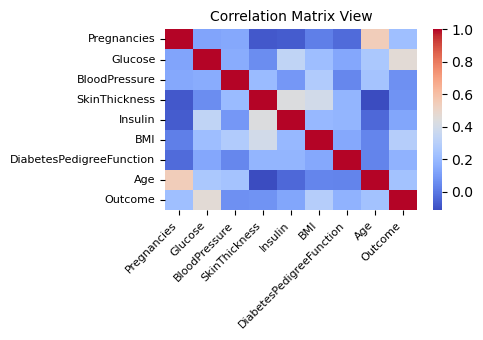

In [12]:
# keeping size small to save pages during printing
plt.figure(figsize=(5, 3.5))
# generating simple correlation matrix heatmap
corr = df.corr()
sns.heatmap(corr, annot=False, cmap='coolwarm')
plt.title('Correlation Matrix View', fontsize=10)
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()